<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# ARIMA Lab

_Authors: Joseph Nelson (DC)_

_Maintainers: David Yerrington (SF)_


---

## Introduction

> ***Note:*** _This can be a pair programming activity or done independently._

The most common application for AR, ARMA, and ARIMA models is inventory planning. Planning inventory for a small shop can be difficult enough, but you've just been hired to plan inventory for a _big_ store - Walmart

In this lab, you will be analyzing weekly Walmart sales data over a two year period from 2010 to 2012. The data is separated by store and by department, but you should focus on analyzing one store for simplicity. Your supervisor has set out the following goals for this project:

1. Record any observed trends in the data
1. Produce a trained model to predict future sales numbers
1. Include useful AND COMMENT ON how graphs (ACF, PACF) impact your modelling decisions throughout your notebook.

Try your best to tune your model. It can be difficult, but don't worry - timeseries analysis is just a difficult and specialized topic.


- Assemble observations and graphs as well as timeseries models in a notebook.

> **Maintenance Note** 
>
> The latest version of Statsmodels still uses older resources in Pandas to deal with some datetime features.  There are warnings associated with the `plot_acf` and `plot_pacf` features from Statsmodels which are non-critical.  We will be surpressing warnings of these features until Statsmodels updates their code. 
>
> You can follow all the fun details about why we still see warnings for these features here:  
>
> https://github.com/statsmodels/statsmodels/issues/3814


In [1]:
import numpy as np

np.warnings.filterwarnings("ignore")
from pandas.core import datetools
np.warnings.resetwarnings()

In [2]:
#### Starter code
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_model import AR, ARIMA, ARMA

%matplotlib inline

# Import data as DataFrame
data = pd.read_csv('./datasets/train.csv')
data.set_index('Date', inplace=True)
data.head()

/anaconda3/lib/python3.7/site-packages/statsmodels/base/wrapper.py:100: DeprecationWarning: `formatargspec` is deprecated since Python 3.5. Use `signature` and the `Signature` object directly
  defaults=argspec[3])
/anaconda3/lib/python3.7/importlib/_bootstrap.py:219: ImportWarning: can't resolve package from __spec__ or __package__, falling back on __name__ and __path__
  return f(*args, **kwds)


,Store,Dept,Weekly_Sales,IsHoliday
Date,,,,
2010-02-05,1,1,24924.50,False
2010-02-12,1,1,46039.49,True
2010-02-19,1,1,41595.55,False
2010-02-26,1,1,19403.54,False
2010-03-05,1,1,21827.90,False


#### Deliverable

**Look back at the readme from wednesday's lecture on timeseries for good information about these models and acf/pacf plots!**

1. Filter the dataframe to Store 1 sales and aggregate over departments to compute the total sales per store.
- Plot the rolling_mean for `Weekly_Sales`. What general trends do you observe?
- Compute the 1, 2, 52 autocorrelations for `Weekly_Sales` and create an autocorrelation and partial autocorrelation plot.
- *BONUS:* What do the acf() and pacf() plots say about the type of model you want to build?
- Split the weekly sales data in a training and test set - using 75% of the data for training.
- "Difference" the data by converting the sales into change in sales (diff function is convenient for doing this.)
- Create an AR(1) model on the training data and compute the mean absolute error of the predictions. How effective is this model?
- Plot the residuals - where are their significant errors?
- Compute and AR(2) model and an ARMA(2, 2) model - does this improve your mean absolute error on the held out set?
- Assemble your findings, including any useful graphs.

#### Additional Resources

1. [ARMA Example](http://statsmodels.sourceforge.net/devel/examples/notebooks/generated/tsa_arma.html)
2. [ARMA Models for TSA](https://www.quantstart.com/articles/Autoregressive-Moving-Average-ARMA-p-q-Models-for-Time-Series-Analysis-Part-1)

In [3]:
data.dtypes

Store             int64
Dept              int64
Weekly_Sales    float64
IsHoliday          bool
dtype: object

#### 1. Filter the dataframe to Store 1 sales and aggregate over departments to compute the total sales per store.

In [4]:
store1 = data[data.Store == 1]
# there are about 36 different stores in this dataset.
store1.head()

,Store,Dept,Weekly_Sales,IsHoliday
Date,,,,
2010-02-05,1,1,24924.50,False
2010-02-12,1,1,46039.49,True
2010-02-19,1,1,41595.55,False
2010-02-26,1,1,19403.54,False
2010-03-05,1,1,21827.90,False


In [5]:
store1_sales = pd.DataFrame(store1['Weekly_Sales'].groupby(store1.index).sum())
store1_sales.head()
# Grouped weekly sales by store 1

,Weekly_Sales
Date,
2010-02-05,1643690.90
2010-02-12,1641957.44
2010-02-19,1611968.17
2010-02-26,1409727.59
2010-03-05,1554806.68


In [6]:
# Update index to datetime type
store1_sales.index = pd.to_datetime(store1_sales.index)

# Check index type to verify series type is expected
store1_sales.index.dtype

dtype('<M8[ns]')

In [7]:
# Check dataframe for expected data
store1_sales.head()

,Weekly_Sales
Date,
2010-02-05,1643690.90
2010-02-12,1641957.44
2010-02-19,1611968.17
2010-02-26,1409727.59
2010-03-05,1554806.68


#### 2. Plot the rolling_mean for Weekly_Sales. What general trends do you observe?

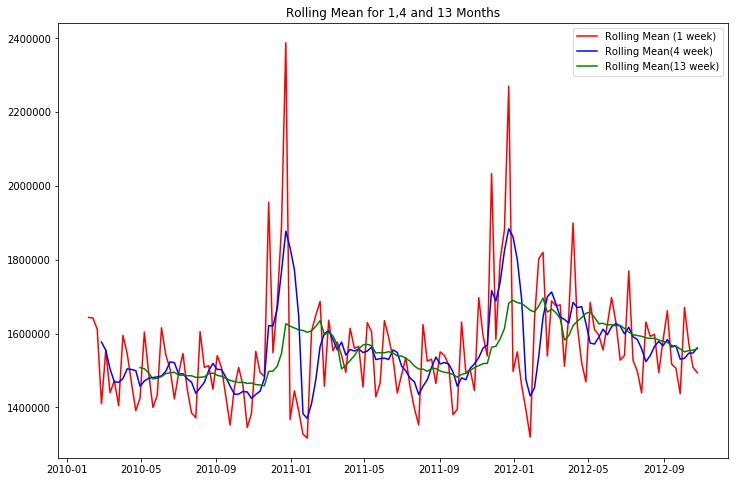

In [8]:
rolmean1  = store1_sales.rolling(window = 1).mean()
rolmean4  = store1_sales.rolling(window = 4).mean()
rolmean13 = store1_sales.rolling(window = 13).mean()

fig = plt.figure(figsize=(12, 8))
mean = plt.plot(rolmean1, color='red', label='Rolling Mean (1 week)')
mean = plt.plot(rolmean4, color='blue', label='Rolling Mean(4 week)')
mean = plt.plot(rolmean13, color='green', label='Rolling Mean(13 week)')

plt.legend(loc='best')
plt.title('Rolling Mean for 1,4 and 13 Months')
plt.show()

There are clearly spikes in the early year around january and february.  Most likely the result of huge increases for holiday spending in November and December.

These spikes are follew by sharp falls which could indicate either that there is a leading up and sudden drop off before and then after the holidays and or, there is a significant decrease in spending immediately following the holiday season.

I choose to Plot 1, 4 and 13 weeks, because those represent week to week as a default for comparison, 4 weeks is about a month and 13 weeks is a season (3 months)

#### 3. Compute the 1, 2, 52 autocorrelations for Weekly_Sales and create an autocorrelation and partial autocorrelation plot.

In [9]:
print('1 Week Lag AutoCorr', store1_sales['Weekly_Sales'].autocorr(lag=1))
print('2 Week Lag AutoCorr', store1_sales['Weekly_Sales'].autocorr(lag=2))
print('52 Week Lag AutoCorr', store1_sales['Weekly_Sales'].autocorr(lag=52))


1 Week Lag AutoCorr 0.3021582794113126
2 Week Lag AutoCorr 0.12741313055390097
52 Week Lag AutoCorr 0.8953760294777008


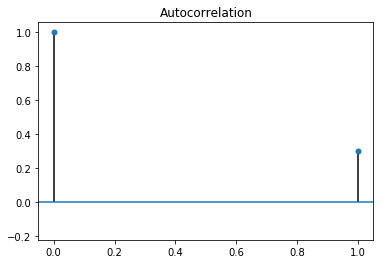

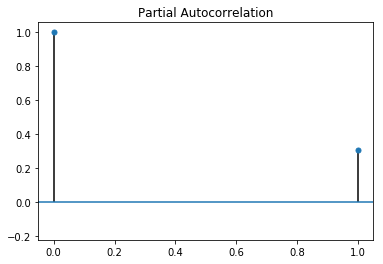

In [10]:
# 1 Month Autocorr and Partial Autocorr
plot_acf(store1_sales, lags = 1)
plot_pacf(store1_sales, lags = 1)

# If you do not use plt.show() it will plot the same vize twice.
# This may be a bug you can fix and submit, to contribute to open source!
plt.show()


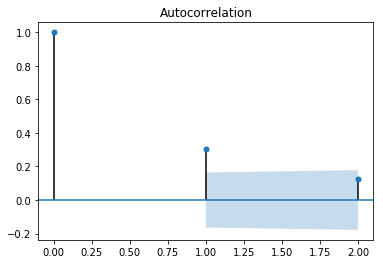

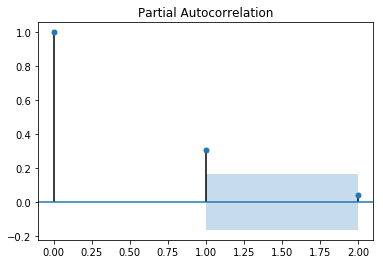

In [11]:
# 2 Month Autocorr and Partial Autocorr

plot_acf(store1_sales, lags =2)
plot_pacf(store1_sales, lags =2)

plt.show()

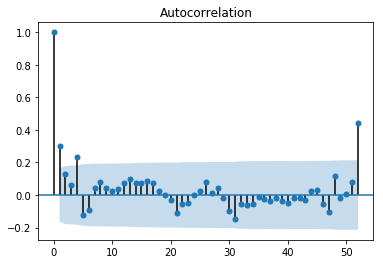

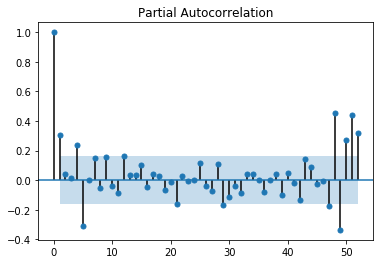

In [12]:
# 52 Month Autocorr and Partial Autocorr
plot_acf(store1_sales, lags =52)
plot_pacf(store1_sales, lags =52)

plt.show()

## 4. BONUS: What do the acf() and pacf() plots say about the type of model you want to build?

The filled blue space is representative of 95% confidence interval.  That being said, those points the we see inside the blue space are likely to be noise an not prove to have any valuable correlation.  With the default 95% confidence interval we can expect that 5% of observations could fall outside this boundary, and those that do are ones we should consider for further investigation as far as correlation.

There is that one point, the first lagged point.  Look at how correlated it is.  1.0.  WOW!... Why is that there, i don't know, maybe as a reference but that is representing a lag of 0 or the same point in time, which shocker, is highly correlated with itself.


- lag 1.  There is not enough information for us to create a confidence interval range and justify if that point represented of 1 lag was outside or in it to make a valuealbe assessment of its correlation.

- lag 2. From the confidence range represented we have one point that appears outside but its also the first lagged observation

_For lags of 1 and 2 the Partial Autocorr and Autocorr is the same and no additional inferences can be made_

- lag 52.  Now that we see several lagged periods together we can really begin to access those that stick out from the crowd
> - 1 Week Lag: We would think that a weeks sales would be relative to the week before or after to an extent.
> - 4 Week Lag: 4 Weeks in a month so its like the monthly affect.
> - **5 Week Lag: This is very interesting 5 week negative correlation....**
> - 48 Week Lag: A Month before a year later.
> - 51 Week Lag: the week before a year later, 
> - 52 Week Lag: 52 weeks in a year so this is the same week a year later



#### 5. Split the weekly sales data in a training and test set - using 75% of the data for training.

In [13]:
store1_sales.shape

(143, 1)

In [14]:
# shape of information is 143 rows.  
143 * 0.75
# first 107 rows for training, next 36 rows for testing.

107.25

In [15]:
train = store1_sales.head(107)

In [16]:
test = store1_sales.tail(36)

#### 6.Create an AR(1) model on the training data and compute the mean absolute error of the predictions. 
####    How effective is this model?

In [17]:
train.head()

,Weekly_Sales
Date,
2010-02-05,1643690.90
2010-02-12,1641957.44
2010-02-19,1611968.17
2010-02-26,1409727.59
2010-03-05,1554806.68


In [18]:
train_values = train['Weekly_Sales'].values
train_dates = train.index

AR1 = AR(train_values, train_dates).fit()

/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/base/tsa_model.py:171: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  % freq, ValueWarning)


In [19]:
test.tail()

,Weekly_Sales
Date,
2012-09-28,1437059.26
2012-10-05,1670785.97
2012-10-12,1573072.81
2012-10-19,1508068.77
2012-10-26,1493659.74


In [20]:
test_values = test['Weekly_Sales'].values
test_dates  = test.index

# The AR Predict takes a start and and end date as values and not a list.
start = '2012-02-24'
end   = '2012-10-26'

AR1_pred = AR1.predict(start=start, end = end)

For the AR(1) model we can also use ARMA and ARIMA with specific parameters.

```python

model = ARMA(endog = VALUES, dates = DATES, order = (1,0) )

model = ARIMA(endog = VALUES, dates = DATES, order = (1,0,0) )

```

- ARMA Order is represented as (p,q)
- ARIMA Order is represented as (p,d,q)
> - p = AutoRegression
> - q = Moving Average
> - d = Differences 

In [21]:
from sklearn.metrics import mean_absolute_error

mean_absolute_error(test_values, AR1_pred)

/anaconda3/lib/python3.7/importlib/_bootstrap.py:219: ImportWarning: can't resolve package from __spec__ or __package__, falling back on __name__ and __path__
  return f(*args, **kwds)
/anaconda3/lib/python3.7/importlib/_bootstrap.py:219: ImportWarning: can't resolve package from __spec__ or __package__, falling back on __name__ and __path__
  return f(*args, **kwds)


79376.327781106

On average we're off about $80,000 a week in sales.  considering our range is 1.4m - 1.7m, thats about a 4.5 - 5.5 percent error.

#### 7. Plot the residuals - where are their significant errors?

In [22]:
AR1_residuals = test_values - AR1_pred

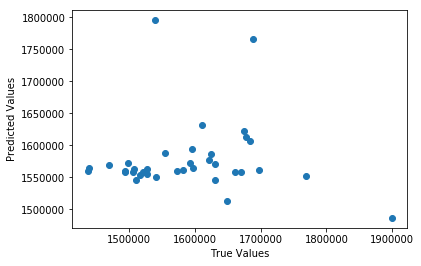

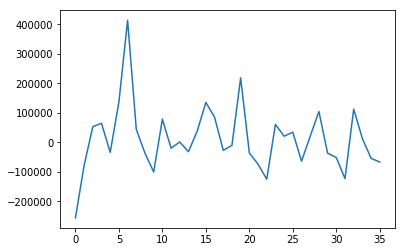

In [23]:
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.scatter(test_values, AR1_pred)
plt.show()

plt.plot(AR1_residuals)
plt.show()

Probably most significant errors would be those 2 major peaks happening at days 6 and 19, which I believe corresponds to 2012-03-30 and 2012-06-29.

#### 8. Compute and AR(2) model and an ARMA(2, 2) model - does this improve your mean absolute error on the held out set?

In [24]:
AR2 = ARIMA(endog = train_values, dates = train_dates, order = (2,0,0)).fit()

# Same start and end we outlined earlier.
AR2_pred = AR2.predict(start=start, end = end)

mean_absolute_error(test_values, AR2_pred)

/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/base/tsa_model.py:171: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  % freq, ValueWarning)


81203.23935441981

In [25]:
AR2_2 = ARIMA(endog = train_values, dates = train_dates, order = (2,0,2)).fit()

# Same start and end we outlined earlier.
AR2_2_pred = AR2_2.predict(start=start, end = end)

mean_absolute_error(test_values, AR2_2_pred)

/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/base/tsa_model.py:171: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  % freq, ValueWarning)


80503.33023424276

Looks like both of the MAE were worse from the original AR, the MAE of the ARMA(2,2) was slightly better than the ARMA(2,0) however.

#### 9. "Difference" this data by converting the sales into change in sales. (Diff function is convenient for doing this.)

We'll do this as part of problem 10 below. The `diff_1` column will contain these values.

#### 10. Difference your data 1, 2, and 3 times. Compute the augmented Dickey-Fuller test and analyze your results. Does it make sense to use an integrated model in this case?

In [26]:
training_data = pd.DataFrame(train_values, columns=['train'])

In [27]:
training_data.head()

,train
0,1643690.90
1,1641957.44
2,1611968.17
3,1409727.59
4,1554806.68


In [28]:
training_data['diff_1'] = training_data['train'].diff()
training_data['diff_2'] = training_data['train'].diff(2)
training_data['diff_3'] = training_data['train'].diff(3)
training_data.head()

,train,diff_1,diff_2,diff_3
0,1643690.90,NaN,NaN,NaN
1,1641957.44,-1733.46,NaN,NaN
2,1611968.17,-29989.27,-31722.73,NaN
3,1409727.59,-202240.58,-232229.85,-233963.31
4,1554806.68,145079.09,-57161.49,-87150.76


In [29]:
from statsmodels.tsa.stattools import adfuller

In [30]:
adfuller(training_data['train'])

(-4.68868182012696,
 8.837054268421641e-05,
 4,
 102,
 {'1%': -3.4961490537199116,
  '5%': -2.8903209639580556,
  '10%': -2.5821223452518263},
 2500.3836879515047)

This output is pretty hard to interpret. Let's use our helper function.

In [31]:
def interpret_dftest(dftest):
    dfoutput = pd.Series(dftest[0:2], index=['Test Statistic','p-value'])
    return dfoutput

In [32]:
interpret_dftest(adfuller(training_data['train']))

Test Statistic   -4.688682
p-value           0.000088
dtype: float64

Our original data is stationary, so we don't need to difference! However, we'll run the augmented Dickey-Fuller test on our other series anyway, as the question asks.

In [33]:
interpret_dftest(adfuller(training_data['diff_1'].dropna()))

Test Statistic   -6.179642e+00
p-value           6.502198e-08
dtype: float64

In [34]:
interpret_dftest(adfuller(training_data['diff_2'].dropna()))

Test Statistic   -5.368909
p-value           0.000004
dtype: float64

In [35]:
interpret_dftest(adfuller(training_data['diff_3'].dropna()))

Test Statistic   -4.772342
p-value           0.000061
dtype: float64

#### 11. Choose a value for d in (p, d, q) based on your results to question 10. Fit an ARIMA (2, d, 2) model. Evaluate the results.

Because our original data are stationary, it makes sense for us to fit an ARIMA model without differencing. That is, ARIMA(2, 0, 2). This will be the same model as our ARMA(2, 2) model.

In [36]:
ARIMA_2_0_2 = ARIMA(endog = train_values, dates = train_dates, order = (2,0,2)).fit()

ARIMA_2_0_2_pred = ARIMA_2_0_2.predict(start=start, end = end)

mean_absolute_error(test_values, ARIMA_2_0_2_pred)

/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/base/tsa_model.py:171: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  % freq, ValueWarning)


80503.33023424276

For the sake of exploring a new model, let's try fitting an ARIMA(2, 1, 2) model to see if it fits any better.

In [37]:
ARIMA_2_1_2 = ARIMA(endog = train_values, dates = train_dates, order = (2,1,2)).fit()

ARIMA_2_1_2_pred = ARIMA_2_1_2.predict(start=start, end = end)

mean_absolute_error(test_values, ARIMA_2_1_2_pred)

/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/base/tsa_model.py:171: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  % freq, ValueWarning)
/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/base/tsa_model.py:171: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  % freq, ValueWarning)
/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/tsatools.py:650: RuntimeWarning: overflow encountered in exp
  newparams = ((1-np.exp(-params))/(1+np.exp(-params))).copy()
/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/tsatools.py:650: RuntimeWarning: invalid value encountered in true_divide
  newparams = ((1-np.exp(-params))/(1+np.exp(-params))).copy()
/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/tsatools.py:651: RuntimeWarning: overflow encountered in exp
  tmp = ((1-np.exp(-params))/(1+np.exp(-params))).copy()
/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/tsatool

LinAlgError: SVD did not converge

Clearly it did not - our algorithm didn't converge! I'll stick with my ARIMA(2, 0, 2) model.

#### 12. Investigate the data for seasonality. Do you observe any seasonal trends? Moving from your ARIMA(2,d,2) model above, choose new values for (P, D, Q, S) and fit the corresponding SARIMAX model.¶

/anaconda3/lib/python3.7/site-packages/statsmodels/regression/linear_model.py:1283: RuntimeWarning: invalid value encountered in sqrt
  return rho, np.sqrt(sigmasq)


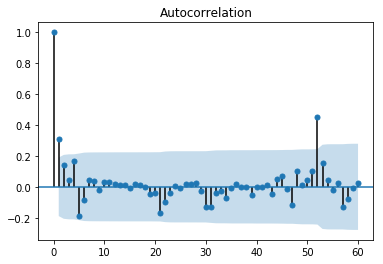

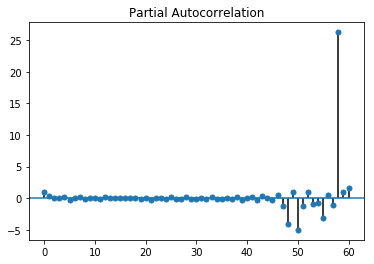

In [38]:
plot_acf(train_values, lags = 60)
plot_pacf(train_values, lags = 60)

plt.show()

It looks like there's a significant lag around a year back. There's a significant autocorrelation at 52 lags. There's a significant partial autocorrelation around 58 weeks. ([Is it an error? Not certain](https://stats.stackexchange.com/questions/305686/what-does-it-mean-if-the-partial-auto-correlation-function-of-a-time-series-have).)

I'll try fitting models with a seasonal period of 52 through 58, just to see what seems to perform best.

In [39]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

/anaconda3/lib/python3.7/importlib/_bootstrap.py:219: ImportWarning: can't resolve package from __spec__ or __package__, falling back on __name__ and __path__
  return f(*args, **kwds)
/anaconda3/lib/python3.7/site-packages/statsmodels/base/wrapper.py:100: DeprecationWarning: `formatargspec` is deprecated since Python 3.5. Use `signature` and the `Signature` object directly
  defaults=argspec[3])


In [40]:
training_data.shape

(107, 4)

In [41]:
import time

In [42]:
t0 = time.time()

final_mae = 9 * (10 ** 25)
final_S = 0
final_D = 0
final_P = 0
final_Q = 0

for S in range(52,59):
    for D in range(5):
        for P in range(5):
            for Q in range(5):
                print(f'Checking ({P}, {D}, {Q}, {S}) at {round(time.time() - t0)} seconds.')
                try:
                    sarima = SARIMAX(endog = training_data['train'].dropna(),
                                     order = (2, 0, 2),
                                     seasonal_order = (P, D, Q, S)).fit()

                    sarima_pred = sarima.predict(start=start, end = end)

                    if mean_absolute_error(test_values, sarima_pred) < final_mae:
                        final_mae = mean_absolute_error(test_values, sarima_pred)
                        final_S = S
                        final_D = D
                        final_P = P
                        final_Q = Q
                        
                    print(f'We just fit a SARIMAX(2, 0, 2)x({P}, {D}, {Q}, {S}) model with {mean_absolute_error(test_values, sarima_pred)} MAE.')
                    
                except:
                    pass

print(f'The final model is SARIMAX(2, 0, 2)x({final_P}, {final_D}, {final_Q}, {final_S}).')
print(f'The test Mean Absolute Error of the final model is {final_mae}.')

Checking (0, 0, 0, 52) at 0 seconds.
Checking (0, 0, 1, 52) at 0 seconds.
Checking (0, 0, 2, 52) at 0 seconds.
Checking (0, 0, 3, 52) at 0 seconds.
Checking (0, 0, 4, 52) at 0 seconds.
Checking (1, 0, 0, 52) at 0 seconds.
Checking (1, 0, 1, 52) at 0 seconds.
Checking (1, 0, 2, 52) at 0 seconds.
Checking (1, 0, 3, 52) at 0 seconds.
Checking (1, 0, 4, 52) at 0 seconds.
Checking (2, 0, 0, 52) at 0 seconds.
Checking (2, 0, 1, 52) at 0 seconds.
Checking (2, 0, 2, 52) at 0 seconds.
Checking (2, 0, 3, 52) at 0 seconds.
Checking (2, 0, 4, 52) at 0 seconds.
Checking (3, 0, 0, 52) at 0 seconds.
Checking (3, 0, 1, 52) at 0 seconds.
Checking (3, 0, 2, 52) at 0 seconds.
Checking (3, 0, 3, 52) at 0 seconds.
Checking (3, 0, 4, 52) at 0 seconds.
Checking (4, 0, 0, 52) at 0 seconds.
Checking (4, 0, 1, 52) at 0 seconds.
Checking (4, 0, 2, 52) at 0 seconds.
Checking (4, 0, 3, 52) at 0 seconds.
Checking (4, 0, 4, 52) at 0 seconds.
Checking (0, 1, 0, 52) at 0 seconds.
Checking (0, 1, 1, 52) at 0 seconds.
C

/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/statespace/sarimax.py:1051: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if self.state_error and params_variance == []:


Checking (0, 1, 1, 53) at 5 seconds.
Checking (0, 1, 2, 53) at 5 seconds.
Checking (0, 1, 3, 53) at 5 seconds.
Checking (0, 1, 4, 53) at 5 seconds.
Checking (1, 1, 0, 53) at 5 seconds.
Checking (1, 1, 1, 53) at 5 seconds.
Checking (1, 1, 2, 53) at 5 seconds.
Checking (1, 1, 3, 53) at 5 seconds.
Checking (1, 1, 4, 53) at 5 seconds.
Checking (2, 1, 0, 53) at 5 seconds.
Checking (2, 1, 1, 53) at 5 seconds.
Checking (2, 1, 2, 53) at 6 seconds.
Checking (2, 1, 3, 53) at 6 seconds.
Checking (2, 1, 4, 53) at 6 seconds.
Checking (3, 1, 0, 53) at 6 seconds.
Checking (3, 1, 1, 53) at 6 seconds.
Checking (3, 1, 2, 53) at 6 seconds.
Checking (3, 1, 3, 53) at 6 seconds.
Checking (3, 1, 4, 53) at 6 seconds.
Checking (4, 1, 0, 53) at 6 seconds.
Checking (4, 1, 1, 53) at 6 seconds.
Checking (4, 1, 2, 53) at 6 seconds.
Checking (4, 1, 3, 53) at 6 seconds.
Checking (4, 1, 4, 53) at 6 seconds.
Checking (0, 2, 0, 53) at 6 seconds.
Checking (0, 2, 1, 53) at 6 seconds.
Checking (0, 2, 2, 53) at 6 seconds.
C

Checking (1, 0, 3, 55) at 9 seconds.
Checking (1, 0, 4, 55) at 9 seconds.
Checking (2, 0, 0, 55) at 9 seconds.
Checking (2, 0, 1, 55) at 9 seconds.
Checking (2, 0, 2, 55) at 9 seconds.
Checking (2, 0, 3, 55) at 9 seconds.
Checking (2, 0, 4, 55) at 9 seconds.
Checking (3, 0, 0, 55) at 9 seconds.
Checking (3, 0, 1, 55) at 9 seconds.
Checking (3, 0, 2, 55) at 9 seconds.
Checking (3, 0, 3, 55) at 9 seconds.
Checking (3, 0, 4, 55) at 9 seconds.
Checking (4, 0, 0, 55) at 9 seconds.
Checking (4, 0, 1, 55) at 9 seconds.
Checking (4, 0, 2, 55) at 9 seconds.
Checking (4, 0, 3, 55) at 9 seconds.
Checking (4, 0, 4, 55) at 9 seconds.
Checking (0, 1, 0, 55) at 9 seconds.
Checking (0, 1, 1, 55) at 10 seconds.
Checking (0, 1, 2, 55) at 10 seconds.
Checking (0, 1, 3, 55) at 10 seconds.
Checking (0, 1, 4, 55) at 10 seconds.
Checking (1, 1, 0, 55) at 10 seconds.
Checking (1, 1, 1, 55) at 10 seconds.
Checking (1, 1, 2, 55) at 10 seconds.
Checking (1, 1, 3, 55) at 10 seconds.
Checking (1, 1, 4, 55) at 10 s

Checking (0, 0, 1, 57) at 14 seconds.
Checking (0, 0, 2, 57) at 14 seconds.
Checking (0, 0, 3, 57) at 14 seconds.
Checking (0, 0, 4, 57) at 14 seconds.
Checking (1, 0, 0, 57) at 14 seconds.
Checking (1, 0, 1, 57) at 14 seconds.
Checking (1, 0, 2, 57) at 14 seconds.
Checking (1, 0, 3, 57) at 14 seconds.
Checking (1, 0, 4, 57) at 14 seconds.
Checking (2, 0, 0, 57) at 14 seconds.
Checking (2, 0, 1, 57) at 14 seconds.
Checking (2, 0, 2, 57) at 14 seconds.
Checking (2, 0, 3, 57) at 14 seconds.
Checking (2, 0, 4, 57) at 14 seconds.
Checking (3, 0, 0, 57) at 14 seconds.
Checking (3, 0, 1, 57) at 14 seconds.
Checking (3, 0, 2, 57) at 14 seconds.
Checking (3, 0, 3, 57) at 14 seconds.
Checking (3, 0, 4, 57) at 14 seconds.
Checking (4, 0, 0, 57) at 14 seconds.
Checking (4, 0, 1, 57) at 14 seconds.
Checking (4, 0, 2, 57) at 14 seconds.
Checking (4, 0, 3, 57) at 14 seconds.
Checking (4, 0, 4, 57) at 14 seconds.
Checking (0, 1, 0, 57) at 14 seconds.
Checking (0, 1, 1, 57) at 14 seconds.
Checking (0,

Checking (4, 3, 2, 58) at 15 seconds.
Checking (4, 3, 3, 58) at 15 seconds.
Checking (4, 3, 4, 58) at 15 seconds.
Checking (0, 4, 0, 58) at 15 seconds.
Checking (0, 4, 1, 58) at 15 seconds.
Checking (0, 4, 2, 58) at 15 seconds.
Checking (0, 4, 3, 58) at 15 seconds.
Checking (0, 4, 4, 58) at 15 seconds.
Checking (1, 4, 0, 58) at 15 seconds.
Checking (1, 4, 1, 58) at 15 seconds.
Checking (1, 4, 2, 58) at 15 seconds.
Checking (1, 4, 3, 58) at 15 seconds.
Checking (1, 4, 4, 58) at 15 seconds.
Checking (2, 4, 0, 58) at 15 seconds.
Checking (2, 4, 1, 58) at 15 seconds.
Checking (2, 4, 2, 58) at 15 seconds.
Checking (2, 4, 3, 58) at 15 seconds.
Checking (2, 4, 4, 58) at 15 seconds.
Checking (3, 4, 0, 58) at 15 seconds.
Checking (3, 4, 1, 58) at 15 seconds.
Checking (3, 4, 2, 58) at 15 seconds.
Checking (3, 4, 3, 58) at 15 seconds.
Checking (3, 4, 4, 58) at 15 seconds.
Checking (4, 4, 0, 58) at 15 seconds.
Checking (4, 4, 1, 58) at 15 seconds.
Checking (4, 4, 2, 58) at 15 seconds.
Checking (4,

In attempting to fit all of these SARIMA models, none of these models are able to fit. It's clear that fitting a seasonal model for any reasonable value of $S$ is not working. 

In large part, this is due to the fact that we have only 107 observations. Setting a seasonal component of 50+ weeks seems silly; there are only two seasons at most. I'm going to **not** fit a seasonal component.

#### 10. Assemble your findings, including any useful graphs.

In [43]:
ARIMA_2_0_2 = ARIMA(endog = train_values, dates = train_dates, order = (2,0,2)).fit()

ARIMA_2_0_2_pred = ARIMA_2_0_2.predict(start=start, end = end)

mean_absolute_error(test_values, ARIMA_2_0_2_pred)

/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/base/tsa_model.py:171: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  % freq, ValueWarning)


80503.33023424276

In [44]:
ARIMA_2_0_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              ARMA Model Results                              
==============================================================================
Dep. Variable:                      y   No. Observations:                  107
Model:                     ARMA(2, 2)   Log Likelihood               -1425.781
Method:                       css-mle   S.D. of innovations         144107.624
Date:                Wed, 09 Jan 2019   AIC                           2863.563
Time:                        00:59:58   BIC                           2879.600
Sample:                    02-05-2010   HQIC                          2870.064
                         - 02-17-2012                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.544e+06   1.92e+04     80.320      0.000    1.51e+06    1.58e+06
ar.L1.y       -1.0398      0.090    -11.583      0.000      -1.216      -0.864
ar.L2.y       -0.4701      0.087     -5.380      0.000      -0.641      -0.299
ma.L1.y        1.4692      0.058     25.369      0.000       1.356       1.583
ma.L2.y        0.9999      0.074     13.532      0.000       0.855       1.145
                                    Roots                                    
=============================================================================
                  Real          Imaginary           Modulus         Frequency
-----------------------------------------------------------------------------
AR.1           -1.1059           -0.9509j            1.4585           -0.3870
AR.2           -1.1059           +0.9509j            1.4585            0.3870
MA.1           -0.7347           -0.6785j            1.0001           -0.3813
MA.2           -0.7347           +0.6785j            1.0001            0.3813
-----------------------------------------------------------------------------
"""

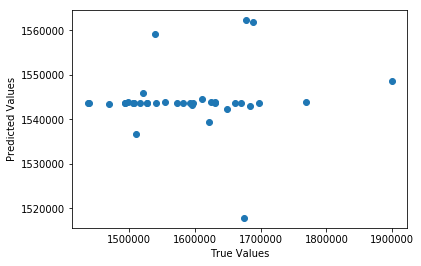

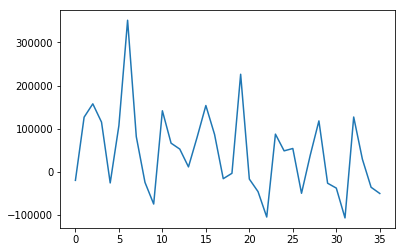

In [45]:
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.scatter(test_values, ARIMA_2_0_2_pred)
plt.show();

plt.plot(test_values - ARIMA_2_0_2_pred)
plt.show();